In [10]:
import numpy as np
import matplotlib.pyplot as plt

In [11]:
def read_last_output(path):
    lines = open(path).readlines()
    i = [i for i, line in enumerate(lines) if line.strip().startswith("Output")][-1]
    n = int(lines[i].split()[1])
    return np.loadtxt(lines[i + 2:i + 2 + n])

def plot(ax, data, **kwargs):
    ax.plot(data[:, 1], data[:, 2], **kwargs)

In [12]:
out0 = read_last_output("../out/sinus1d_level6_old.out")
out1 = read_last_output("../out/sinus1d_level6_1dof.out")
out2 = read_last_output("../out/sinus1d_level5_2dof.out")
out3 = read_last_output("../out/sinus1d_level5_old.out")

In [13]:
assert np.array_equal(out0, out1)

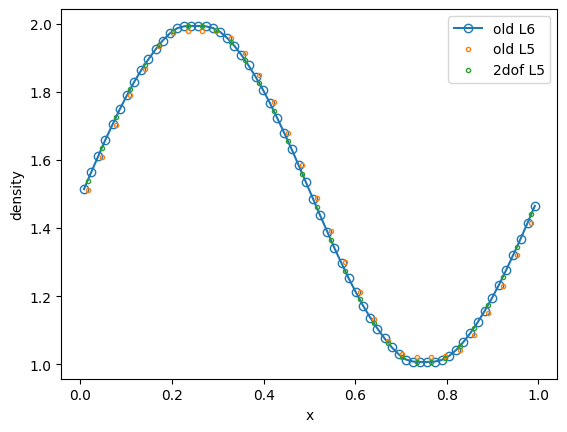

In [14]:
fig, ax = plt.subplots()

plot(ax, out0, label="old L6", marker='o', mfc="none")
plot(ax, out3, label="old L5", marker='.', mfc="none", linestyle='none')
plot(ax, out2, label="2dof L5", marker='.', mfc="none", linestyle='none')

ax.set_xlabel("x")
ax.set_ylabel("density")
ax.legend()

In [15]:
def read_last_time(path):
    """
    example line that includes the final time
        Fine step= 175 t= 1.00198E+00 dt= 5.726E-03 a= 1.000E+00 mem=1.6% 
    """
    with open(path, "r") as f:
        lines = f.readlines()
    for line in reversed(lines):
        if "t=" in line:
            parts = line.split()
            for part1, part2 in zip(parts[:-1], parts[1:]):
                if part1 == "t=":
                    return float(part2)

In [16]:
path4 = "../out/sinus1d_level5_p3.out"
out4 = read_last_output(path4)
t4 = read_last_time(path4)

In [17]:
def analytical_solution(x, t):
    rho_min = 1.0
    rho_max = 2.0
    vx = 1.0

    y = x - vx * t
    rho = rho_min + (rho_max - rho_min) * 0.5 * (1 + np.sin(2.0 * np.pi * y))
    return rho

def get_cell_average(f, x, p):
    n = len(x)
    h = (x[-1] - x[0]) / n
    # Gauss-Legendre quadrature
    x_gauss, w_gauss = np.polynomial.legendre.leggauss(-(-(p+1)//2))
    x_gauss *= h / 2.0
    w_gauss *= h / 2.0

    cell_averages = np.zeros(n)
    for i, x_center in enumerate(x):
        x_cell = x_center + x_gauss
        cell_averages[i] = np.sum(w_gauss * f(x_cell))
    return cell_averages

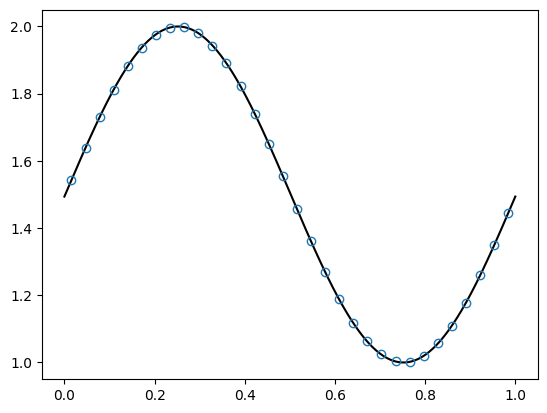

In [18]:
fig, ax = plt.subplots()

xfine = np.linspace(0.0, 1.0, 1000)
ax.plot(xfine, analytical_solution(xfine, t4), color='k')

plot(ax, out4, linestyle='none', marker='o', mfc='none', label='p=3')